#Mapping Data Files into one Usable Dataset

##Clinical Parameters Cleanup and Visualization
Since the clinical data (like ER status, relapse status, lymph node status) is being pulled from the GEO Omnibus, it must be converted into a format that is machine readable. When downloading from the source, it downloads as a txt. This section below formats the txt into a dataframe. It also renames some of the key column headers, so that they will match the other data files.

In [1]:
'''Converting Clinical Data txt file into dataframe'''
import pandas as pd
import matplotlib.pyplot as plt
clinical_data = pd.read_csv('clinical_data.txt', sep="\t")
#print (clinical_data)
clinical_parameters_df = pd.DataFrame(clinical_data)
'''renaming the column names to avoid any special character issues down the line'''
clinical_parameters_df.rename(columns={"GEO asscession number":"Sample_Accession", "relapse (1=True)":"Relapse", "ER Status":"ER_status"},inplace=True)
print (clinical_parameters_df)

     PID Sample_Accession lymph node status  \
0      3         GSM36793          negative   
1      5         GSM36796          negative   
2      6         GSM36797          negative   
3      7         GSM36798          negative   
4      8         GSM36800          negative   
..   ...              ...               ...   
281  900         GSM36887          negative   
282  901         GSM36889          negative   
283  903         GSM36892          negative   
284  909         GSM36894          negative   
285  913         GSM36911          negative   

     time to relapse or last follow-up (months)  Relapse ER_status  \
0                                           101        0       ER-   
1                                           118        0       ER+   
2                                             9        1       ER-   
3                                           106        0       ER-   
4                                            37        1       ER-   
..             

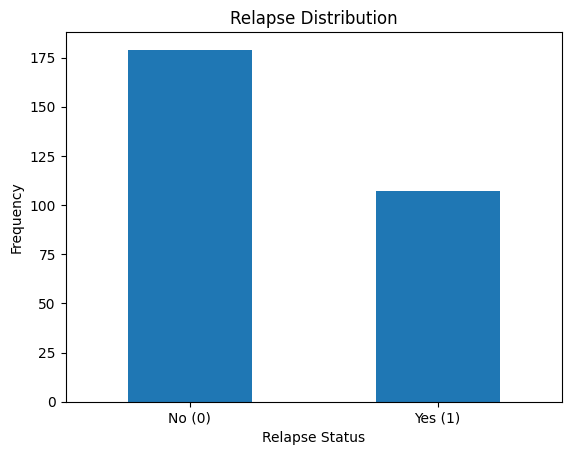

Relapse Count Relapse
0    179
1    107
Name: count, dtype: int64
Relapse Percentage Relapse
0    62.587413
1    37.412587
Name: count, dtype: float64


In [2]:
'''Distribution of how many patients relapsed versus relapse free'''
relapse_counts = clinical_parameters_df['Relapse'].value_counts()

'''Plotting and customizing the look of the plot'''
relapse_counts.plot(kind='bar', rot=0)
plt.title('Relapse Distribution')
plt.xlabel('Relapse Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()
#print (relapse_counts)

'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
relapse_percentage = ((relapse_counts / len(clinical_parameters_df)) * 100)
print("Relapse Count", relapse_counts)
print("Relapse Percentage", relapse_percentage)


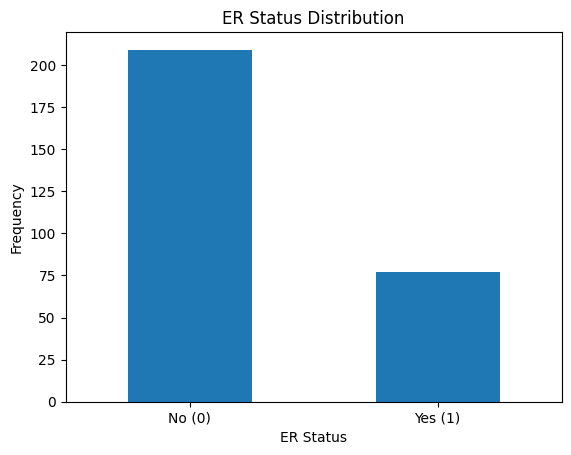

Relapse Count ER_status
ER+    209
ER-     77
Name: count, dtype: int64
Relapse Percentage ER_status
ER+    73.076923
ER-    26.923077
Name: count, dtype: float64


In [3]:
'''Distribution of ER Status'''
ER_counts = clinical_parameters_df['ER_status'].value_counts()

'''Plotting and customizing the look of the plot'''
ER_counts.plot(kind='bar', rot=0)
plt.title('ER Status Distribution')
plt.xlabel('ER Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()


'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
ER_percentage = ((ER_counts / len(clinical_parameters_df)) * 100)
print("Relapse Count", ER_counts)
print("Relapse Percentage", ER_percentage)

#Master File

##Investigation of Master file
First order of business is to reference the P/A/M file and remove any absent signals. Then reference the p-value files and remove any cells that do not meet the 0.05 threshold. Then we review how much of the data was removed.
I think it makes sense to do it this way first, and then map the files together, to keep the data as nimble as possible?

In [4]:
'''Turn master file into dataframe'''
gene_seq_data = pd.read_csv('GSE2034_family_expression_matrix.csv', sep=",")
gene_seq_df = pd.DataFrame(gene_seq_data)
print (gene_seq_df)

               ID_REF  GSM36777  GSM36778  GSM36779  GSM36780  GSM36781  \
0      AFFX-BioB-5_at     467.7     754.0     981.4     899.2     730.1   
1      AFFX-BioB-M_at     919.8    1663.8    2094.1    1733.8    1592.3   
2      AFFX-BioB-3_at     468.3     996.3    1029.3     906.8     637.0   
3      AFFX-BioC-5_at    1371.1    2511.1    2699.7    2756.9    2158.4   
4      AFFX-BioC-3_at    1048.2    1930.7    1941.4    1658.2    1675.9   
...               ...       ...       ...       ...       ...       ...   
22278     222380_s_at     423.1    1911.9     186.3     378.6     726.5   
22279       222381_at      36.9     134.5      90.4     153.1      98.4   
22280     222382_x_at     120.2      27.9      69.9     170.3     189.4   
22281     222383_s_at      18.7      42.7      10.5       5.5      23.2   
22282       222384_at      89.4      33.9      57.7      21.8      23.2   

       GSM36782  GSM36783  GSM36784  GSM36785  ...  GSM37053  GSM37054  \
0         838.5     756.9

In [5]:
'''Turn P/A/M file into dataframe'''
PAM_data= pd.read_csv('GSE2034_family_matrix_ABS_CALL.csv', sep=",")
PAM_data_df = pd.DataFrame(PAM_data)
print (PAM_data_df)

               ID_REF GSM36777 GSM36778 GSM36779 GSM36780 GSM36781 GSM36782  \
0      AFFX-BioB-5_at        P        P        P        P        P        P   
1      AFFX-BioB-M_at        P        P        P        P        P        P   
2      AFFX-BioB-3_at        P        P        P        P        P        P   
3      AFFX-BioC-5_at        P        P        P        P        P        P   
4      AFFX-BioC-3_at        P        P        P        P        P        P   
...               ...      ...      ...      ...      ...      ...      ...   
22278     222380_s_at        P        P        P        P        P        P   
22279       222381_at        A        A        A        A        A        A   
22280     222382_x_at        A        A        A        P        A        A   
22281     222383_s_at        A        A        A        A        A        A   
22282       222384_at        A        A        A        A        A        A   

      GSM36783 GSM36784 GSM36785  ... GSM37053 GSM3

In [6]:
'''Turn p-value file into dataframe'''
P_data= pd.read_csv('GSE2034_family_matrix_DETECTION_P_VALUE.csv', sep=",")
P_data_df = pd.DataFrame(P_data)
print (P_data_df)

               ID_REF  GSM36777  GSM36778  GSM36779  GSM36780  GSM36781  \
0      AFFX-BioB-5_at  0.002023  0.001248  0.000390  0.000972  0.001593   
1      AFFX-BioB-M_at  0.000081  0.000044  0.000044  0.000052  0.000095   
2      AFFX-BioB-3_at  0.000195  0.000052  0.000052  0.000060  0.000127   
3      AFFX-BioC-5_at  0.000127  0.000110  0.000081  0.000110  0.000195   
4      AFFX-BioC-3_at  0.000070  0.000081  0.000070  0.000070  0.000060   
...               ...       ...       ...       ...       ...       ...   
22278     222380_s_at  0.000732  0.000244  0.030273  0.000732  0.000732   
22279       222381_at  0.334473  0.219482  0.111572  0.111572  0.303711   
22280     222382_x_at  0.129639  0.303711  0.171387  0.030273  0.095215   
22281     222383_s_at  0.500000  0.533936  0.919434  0.780518  0.665527   
22282       222384_at  0.067627  0.432373  0.246094  0.432373  0.423828   

       GSM36782  GSM36783  GSM36784  GSM36785  ...  GSM37053  GSM37054  \
0      0.000446  0.000509

In [7]:
'''inspect master file for any missing values'''
import numpy as np

missing_values_master = gene_seq_df.isnull().any(axis=1).sum()
missing_values_PAM = PAM_data_df.isnull().any(axis=1).sum()
missing_values_P = P_data_df.isnull().any(axis=1).sum()

print ("Number of missing data in Master File:", missing_values_master)
print ("Number of missing data in PAM File:", missing_values_PAM)
print ("Number of missing data in P-value File:", missing_values_P)

Number of missing data in Master File: 0
Number of missing data in PAM File: 0
Number of missing data in P-value File: 0


In [8]:
'''Investigating if the columns and rows are exactly the same between all 3 datasets'''


'''Putting Headers in a list to compare'''

master_headers = list(gene_seq_df.columns.values)
PAM_headers = list(PAM_data_df.columns.values)
P_headers = list(P_data_df.columns.values)


'''Testing to see if the lists are identical'''

master_vs_PAM = master_headers == PAM_headers
master_vs_P = master_headers == P_headers

print ("Is Master Header Identical to PAM header:", master_vs_PAM)
print ("Is Master Header Identical to P header:", master_vs_P)


'''Putting values of first column (Probe ID's) in a list to compare'''

master_ProbeID = gene_seq_df['ID_REF'].values.tolist()
PAM_ProbeID = PAM_data_df['ID_REF'].values.tolist()
P_ProbeID = P_data_df['ID_REF'].values.tolist()

'''Comparing Master first column to PAM and Pvalue'''

master_probe_pam = master_ProbeID == PAM_ProbeID
master_probe_p = master_ProbeID == P_ProbeID

print ("Is Master ProbeID Identical to PAM ProbID:", master_probe_pam)
print ("Is Master ProbID Identical to P ProbID:", master_probe_p)

Is Master Header Identical to PAM header: True
Is Master Header Identical to P header: True
Is Master ProbeID Identical to PAM ProbID: True
Is Master ProbID Identical to P ProbID: True


##Quality Assurance of Master File

In [14]:
'''Finding positions of 'A' in PAM dataframe and replacing them in gene_seq_df'''

#Create a boolean mask for values in PAM_data_df that are 'A'
mask_A = PAM_data_df == 'A'

#Use this mask to replace corresponding values in gene_seq_df with 'Absent'
filtered_gene_seq_df = gene_seq_df.mask(mask_A)

print(filtered_gene_seq_df)


               ID_REF  GSM36777  GSM36778  GSM36779  GSM36780  GSM36781  \
0      AFFX-BioB-5_at     467.7     754.0     981.4     899.2     730.1   
1      AFFX-BioB-M_at     919.8    1663.8    2094.1    1733.8    1592.3   
2      AFFX-BioB-3_at     468.3     996.3    1029.3     906.8     637.0   
3      AFFX-BioC-5_at    1371.1    2511.1    2699.7    2756.9    2158.4   
4      AFFX-BioC-3_at    1048.2    1930.7    1941.4    1658.2    1675.9   
...               ...       ...       ...       ...       ...       ...   
22278     222380_s_at     423.1    1911.9     186.3     378.6     726.5   
22279       222381_at       NaN       NaN       NaN       NaN       NaN   
22280     222382_x_at       NaN       NaN       NaN     170.3       NaN   
22281     222383_s_at       NaN       NaN       NaN       NaN       NaN   
22282       222384_at       NaN       NaN       NaN       NaN       NaN   

       GSM36782  GSM36783  GSM36784  GSM36785  ...  GSM37053  GSM37054  \
0         838.5     756.9

In [16]:
'''Finding positions of 'A' in PAM dataframe and replacing them in gene_seq_df'''

ID_REF_col = gene_seq_df["ID_REF"].values.tolist()

#Create a boolean mask for values in P_data_df for values that are larger than our criteria p>0.05
mask_B = P_data_df[master_headers].drop(columns = ['ID_REF']) > 0.05

# mask_B = P_data_df[master_headers] > 0.05 & P_data_df.apply(pd.to_numeric, errors='ignore').notna()

#Use this mask to replace corresponding values that don't fit the criteria in gene_seq_df with 'Not Significant'
p_filtered_gene_seq_df = filtered_gene_seq_df.drop(columns = ['ID_REF']).mask(mask_B, 'Not Significant')

#p_filtered_gene_seq_df = filtered_gene_seq_df.mask(mask_B, 'Not Significant')
#print(p_filtered_gene_seq_df)

'''Put dropped ProbeID column back in'''
QA_filtered_gene_seq_df = p_filtered_gene_seq_df.copy()
QA_filtered_gene_seq_df.insert(0, 'ID_REF', ID_REF_col)

print (QA_filtered_gene_seq_df)

               ID_REF         GSM36777         GSM36778         GSM36779  \
0      AFFX-BioB-5_at            467.7            754.0            981.4   
1      AFFX-BioB-M_at            919.8           1663.8           2094.1   
2      AFFX-BioB-3_at            468.3            996.3           1029.3   
3      AFFX-BioC-5_at           1371.1           2511.1           2699.7   
4      AFFX-BioC-3_at           1048.2           1930.7           1941.4   
...               ...              ...              ...              ...   
22278     222380_s_at            423.1           1911.9            186.3   
22279       222381_at  Not Significant  Not Significant  Not Significant   
22280     222382_x_at  Not Significant  Not Significant  Not Significant   
22281     222383_s_at  Not Significant  Not Significant  Not Significant   
22282       222384_at  Not Significant  Not Significant  Not Significant   

              GSM36780         GSM36781         GSM36782         GSM36783  \
0         

In [34]:
'''how many values were replaced'''
import math

print ('Number of Entries marked Not Significant:', (QA_filtered_gene_seq_df.values == 'Not Significant').sum())
print ('Total Dataframe Size:', QA_filtered_gene_seq_df.size)
proportion_replaced= ((QA_filtered_gene_seq_df.values == 'Not Significant').sum()/QA_filtered_gene_seq_df.size)*100

print ('Amount Replaced:', round(proportion_replaced, 2), '%')

Number of Entries marked Not Significant: 3184984
Total Dataframe Size: 6395221
Amount Replaced: 49.8 %
